# Module 1 — Corporate Finance: Strategic Capital Allocation

**Business question:** Which of NovaFin's strategic initiatives should receive funding?

This notebook follows the capstone's required chain of reasoning:

> **Data → ML prediction of success → NPV / Expected NPV → Fund / Review / Reject**

**Key assumptions** (documented so they can be challenged):
- All monetary values are in **INR crore** (Module 1 convention).
- Annual net cash flow in year *t* = `Revenue_Year_t − Operating_Cost`, with operating cost held constant across the 3-year horizon.
- Per-initiative discount rate `r = Interest_Rate / 100`.
- A **terminal value** captures cash flows beyond year 3: `TV = CF3 × (1+g) / (r−g)` with `g = 3%`, discounted back 3 years. Without it, a 3-year horizon makes almost every project look value-destroying.
- **Expected NPV = P(Success) × NPV** (as fixed by the brief).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Make the src/ package importable (works from the notebooks/ folder)
sys.path.insert(0, str(Path.cwd().parent / "src"))
sys.path.insert(0, str(Path.cwd() / "src"))

from novafin.config import SEED, apply_plot_style, output_dir
from novafin.data import load_strategic_initiatives
from novafin.evaluation import classification_scores, compare_models
from novafin.finance import npv, expected_npv

apply_plot_style()
OUT = output_dir("module1")
TARGET = "Historical_Success"
TERMINAL_GROWTH = 0.03
print("Seed:", SEED, "| outputs ->", OUT)

Seed: 42 | outputs -> C:\Users\rahul\Desktop\Sheetal\MLF\Capstone project\outputs\module1


## Load data & engineer features

We add a few finance-motivated features that the raw columns don't express directly (total revenue, revenue-to-investment, revenue growth, average annual profit, profit margin).

In [2]:
def engineer_features(df):
    df = df.copy()
    rev = df[["Revenue_Year1", "Revenue_Year2", "Revenue_Year3"]]
    df["Total_Revenue"] = rev.sum(axis=1)
    df["Revenue_to_Investment"] = df["Total_Revenue"] / df["Initial_Investment"]
    df["Revenue_Growth"] = (df["Revenue_Year3"] - df["Revenue_Year1"]) / df["Revenue_Year1"]
    df["Avg_Annual_Profit"] = rev.mean(axis=1) - df["Operating_Cost"]
    df["Profit_Margin"] = df["Avg_Annual_Profit"] / rev.mean(axis=1)
    return df

df = engineer_features(load_strategic_initiatives())
print(df.shape)
df.head()

(180, 19)


,Initiative_ID,Business_Unit,Initial_Investment,Revenue_Year1,Revenue_Year2,Revenue_Year3,Operating_Cost,Expected_ROI,Business_Growth,GDP_Growth,Interest_Rate,Competition_Index,Risk_Rating,Historical_Success,Total_Revenue,Revenue_to_Investment,Revenue_Growth,Avg_Annual_Profit,Profit_Margin
0,1001,SME Lending,131.13,35.21,42.86,45.76,41.72,5.48,5.65,5.56,7.82,50.22,Medium,1,123.83,0.944330,0.299631,-0.443333,-0.010741
1,1002,SME Lending,286.69,111.52,141.54,149.05,89.01,11.38,7.03,4.18,6.63,28.93,Medium,0,402.11,1.402595,0.336532,45.026667,0.335928
2,1003,Wealth,227.64,110.06,130.92,168.77,33.35,15.70,10.44,6.66,7.39,39.86,High,1,409.75,1.799991,0.533436,103.233333,0.755827
3,1004,Digital Banking,191.64,52.38,55.94,69.05,57.62,7.63,4.31,5.80,6.84,45.42,Medium,1,177.37,0.925537,0.318251,1.503333,0.025427
4,1005,Corporate Banking,72.13,25.30,30.84,35.10,15.47,7.82,8.68,6.21,7.12,65.21,Medium,0,91.24,1.264938,0.387352,14.943333,0.491342


## Task 1 — Exploratory Data Analysis

We examine the investment/ROI distributions, success rates across risk categories and business units, and the relationship between growth and ROI.

In [3]:
rate = df[TARGET].mean()
print(f"Rows: {len(df)} | Success rate: {rate:.1%} "
      f"({df[TARGET].sum()} success / {(1 - df[TARGET]).sum():.0f} not)")
df[["Initial_Investment", "Expected_ROI", "Business_Growth", "Profit_Margin"]].describe().round(2)

Rows: 180 | Success rate: 76.7% (138 success / 42 not)


,Initial_Investment,Expected_ROI,Business_Growth,Profit_Margin
count,180.00,180.00,180.00,180.00
mean,157.47,10.77,8.23,0.45
std,79.39,4.83,2.97,0.22
min,31.49,2.00,-1.72,-0.25
25%,89.31,7.31,6.00,0.34
50%,155.32,10.50,8.49,0.47
75%,226.87,14.23,10.08,0.62
max,296.46,22.79,19.56,0.81


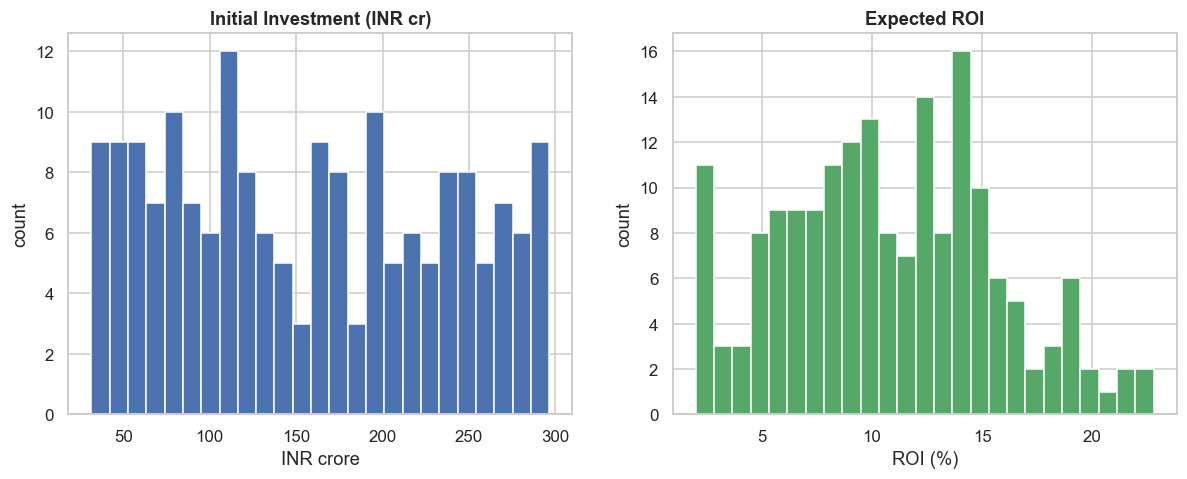

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].hist(df["Initial_Investment"], bins=25, color="#4C72B0")
ax[0].set(title="Initial Investment (INR cr)", xlabel="INR crore", ylabel="count")
ax[1].hist(df["Expected_ROI"], bins=25, color="#55A868")
ax[1].set(title="Expected ROI", xlabel="ROI (%)", ylabel="count")
fig.savefig(OUT / "eda_distributions.png")
plt.show()

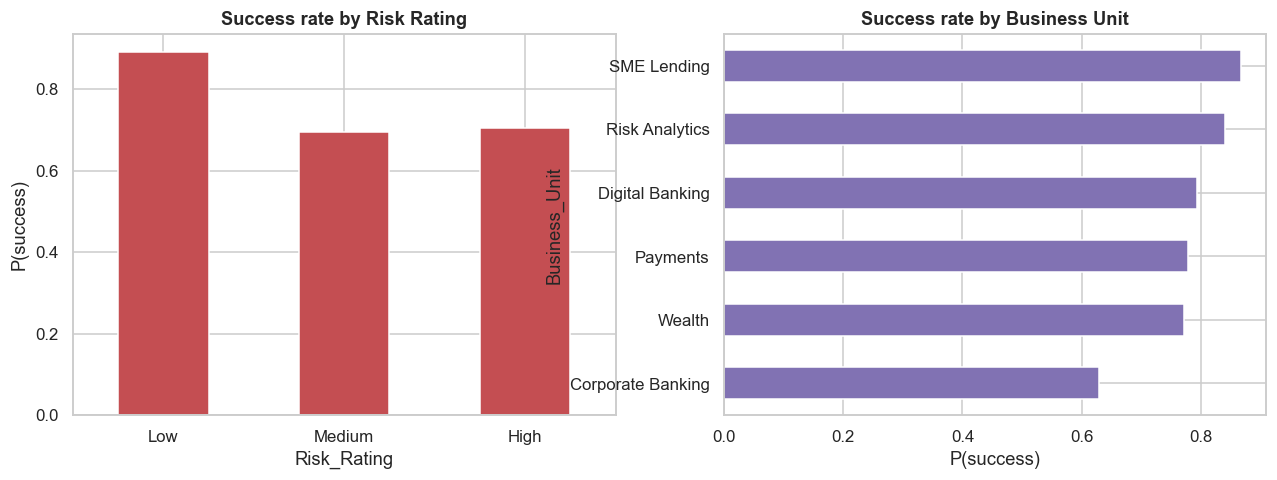

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
df.groupby("Risk_Rating")[TARGET].mean().reindex(["Low", "Medium", "High"]).plot(
    kind="bar", ax=ax[0], color="#C44E52")
ax[0].set(title="Success rate by Risk Rating", ylabel="P(success)")
ax[0].tick_params(axis="x", rotation=0)
df.groupby("Business_Unit")[TARGET].mean().sort_values().plot(
    kind="barh", ax=ax[1], color="#8172B3")
ax[1].set(title="Success rate by Business Unit", xlabel="P(success)")
fig.savefig(OUT / "eda_success_rates.png")
plt.show()

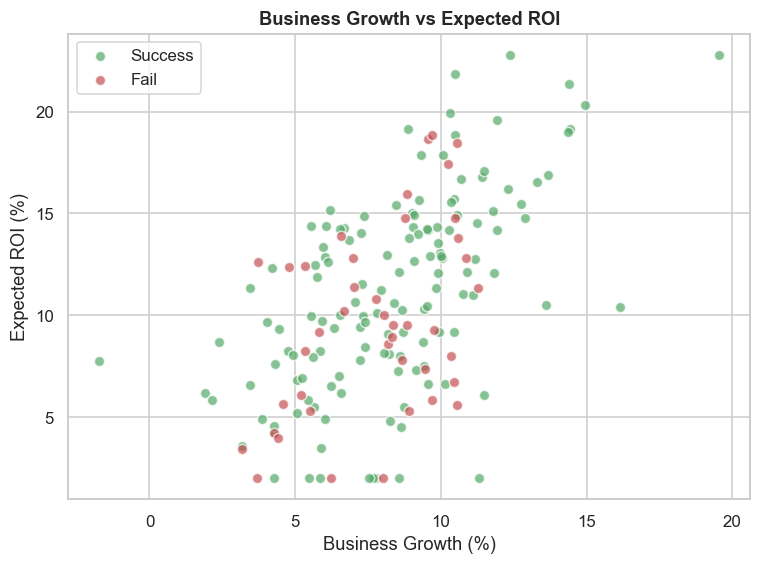

In [6]:
fig, ax = plt.subplots(figsize=(8, 5.5))
for flag, colour, label in [(1, "#55A868", "Success"), (0, "#C44E52", "Fail")]:
    sub = df[df[TARGET] == flag]
    ax.scatter(sub["Business_Growth"], sub["Expected_ROI"], c=colour,
               label=label, alpha=0.7, edgecolor="white", s=45)
ax.set(title="Business Growth vs Expected ROI", xlabel="Business Growth (%)", ylabel="Expected ROI (%)")
ax.legend()
fig.savefig(OUT / "eda_growth_vs_roi.png")
plt.show()

## Task 2 — Predict initiative success

We compare three classifiers with **stratified 5-fold cross-validation**. Because the dataset is small (180 rows), we score using **out-of-fold predicted probabilities** (`cross_val_predict`) — every row is scored by a model that never saw it, giving leakage-free estimates we can reuse for the NPV step. We de-emphasise accuracy in favour of ROC-AUC / PR-AUC given the class imbalance (~77% success).

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

CATEGORICAL = ["Business_Unit", "Risk_Rating"]
NUMERIC = ["Initial_Investment", "Revenue_Year1", "Revenue_Year2", "Revenue_Year3",
           "Operating_Cost", "Expected_ROI", "Business_Growth", "GDP_Growth",
           "Interest_Rate", "Competition_Index", "Total_Revenue",
           "Revenue_to_Investment", "Revenue_Growth", "Avg_Annual_Profit", "Profit_Margin"]

def make_prep():
    return ColumnTransformer([
        ("num", StandardScaler(), NUMERIC),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
    ])

X, y = df[NUMERIC + CATEGORICAL], df[TARGET]
models = {
    "LogisticRegression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "RandomForest": RandomForestClassifier(n_estimators=400, class_weight="balanced", random_state=SEED),
    "GradientBoosting": GradientBoostingClassifier(random_state=SEED),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
results, oof = {}, {}
for name, clf in models.items():
    pipe = Pipeline([("prep", make_prep()), ("clf", clf)])
    proba = cross_val_predict(pipe, X, y, cv=cv, method="predict_proba")[:, 1]
    results[name] = classification_scores(y, proba)
    oof[name] = proba

table = compare_models(results)
table.to_csv(OUT / "model_comparison.csv")
table

,ROC_AUC,PR_AUC,Precision,Recall,F1
LogisticRegression,0.5840,0.8068,0.8144,0.5725,0.6723
RandomForest,0.5260,0.7782,0.7753,1.0000,0.8734
GradientBoosting,0.4862,0.7555,0.7702,0.8986,0.8294


> **Finding / model risk:** ROC-AUC sits near ~0.58 (barely above chance). The provided features have weak power to predict initiative success. We proceed but flag this as **model risk** — the NPV ranking below carries more decision weight than the classifier, and predicted probabilities should be treated as soft signals, not certainties.

In [8]:
best = table.index[0]
print("Best model by ROC-AUC:", best)
p_success = pd.Series(oof[best], index=df.index, name="P_Success")

# Fit the best model on all data for explainability
best_pipe = Pipeline([("prep", make_prep()), ("clf", models[best])]).fit(X, y)

Best model by ROC-AUC: LogisticRegression


Background dataset has 180 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=180 when initializing the masker.


C:\Users\rahul\AppData\Local\Temp\ipykernel_32376\2853891525.py:14: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(values, X_trans, feature_names=feature_names, show=False)


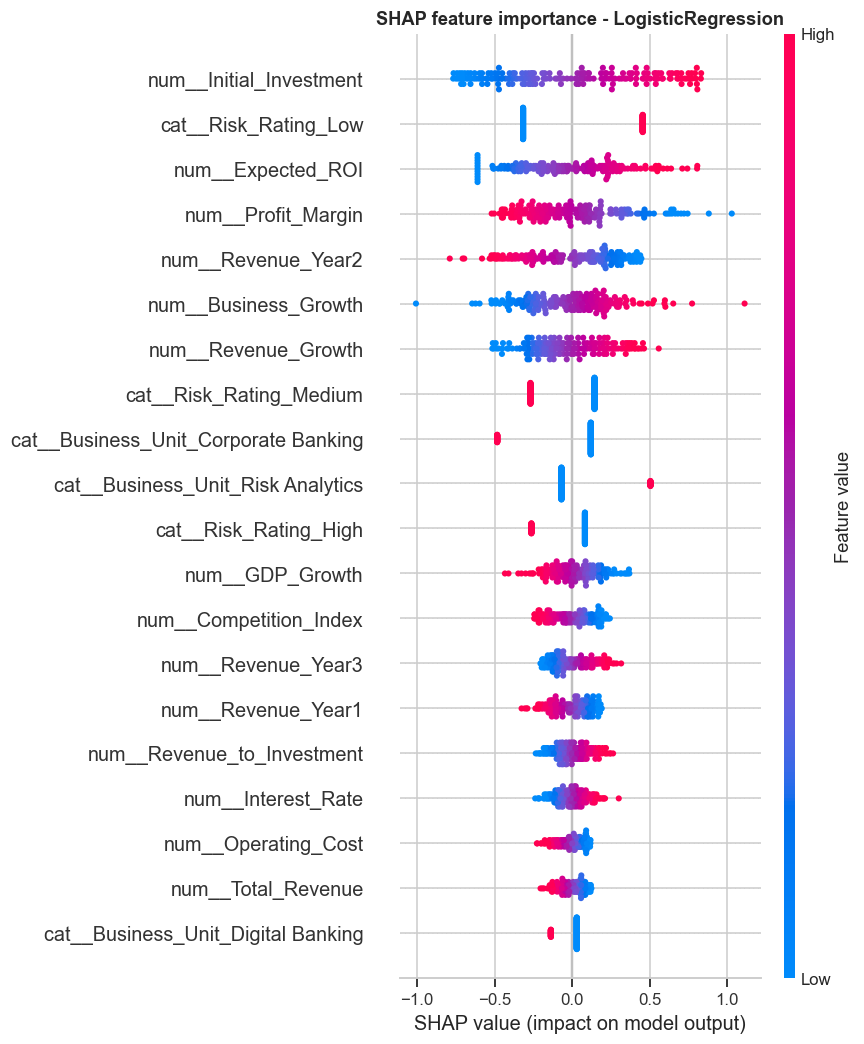

In [9]:
import shap

prep, clf = best_pipe.named_steps["prep"], best_pipe.named_steps["clf"]
X_trans = prep.transform(X)
feature_names = prep.get_feature_names_out()

if hasattr(clf, "estimators_") or best == "GradientBoosting":
    explainer = shap.TreeExplainer(clf)
else:
    explainer = shap.LinearExplainer(clf, X_trans)

sv = explainer(X_trans)
values = sv.values[:, :, 1] if sv.values.ndim == 3 else sv.values
shap.summary_plot(values, X_trans, feature_names=feature_names, show=False)
plt.title(f"SHAP feature importance - {best}")
plt.savefig(OUT / "shap_summary.png", bbox_inches="tight")
plt.show()

## Task 3 — Financial decision: NPV, Expected NPV, Fund / Review / Reject

**Decision rule** (justified rather than blindly adopted):
- **Reject** — negative Expected NPV (destroys capital in expectation).
- **Fund** — positive Expected NPV *and* enough conviction of success (≥60%) at acceptable risk; very high conviction (≥75%) overrides a *High* risk rating.
- **Review** — positive Expected NPV but uncertain and/or risky.

In [10]:
r = df["Interest_Rate"] / 100.0
cash_flows = [df[f"Revenue_Year{t}"] - df["Operating_Cost"] for t in (1, 2, 3)]

explicit_npv = npv(df["Initial_Investment"], cash_flows, r)
terminal_value = cash_flows[2] * (1 + TERMINAL_GROWTH) / (r - TERMINAL_GROWTH)
project_npv = explicit_npv + terminal_value / (1 + r) ** 3
exp_npv = pd.Series(expected_npv(p_success, project_npv), index=df.index)

def classify_decision(en, ps, risk):
    if en <= 0:
        return "Reject"
    if ps >= 0.60 and risk != "High":
        return "Fund"
    if ps >= 0.75:
        return "Fund"
    return "Review"

decisions = pd.DataFrame({
    "Initiative_ID": df["Initiative_ID"],
    "Business_Unit": df["Business_Unit"],
    "Risk_Rating": df["Risk_Rating"],
    "Initial_Investment": df["Initial_Investment"].round(2),
    "P_Success": p_success.round(3),
    "NPV": project_npv.round(2),
    "Expected_NPV": exp_npv.round(2),
})
decisions["Decision"] = [classify_decision(en, ps, rk) for en, ps, rk
                          in zip(decisions.Expected_NPV, decisions.P_Success, decisions.Risk_Rating)]
decisions = decisions.sort_values("Expected_NPV", ascending=False).reset_index(drop=True)
decisions.to_csv(OUT / "initiative_decisions.csv", index=False)
decisions.head(10)

,Initiative_ID,Business_Unit,Risk_Rating,Initial_Investment,P_Success,NPV,Expected_NPV,Decision
0,1075,Wealth,Low,220.85,0.748,3804.94,2845.07,Fund
1,1034,Risk Analytics,Low,286.20,0.777,2818.42,2189.84,Fund
2,1031,Wealth,Medium,194.04,0.449,4730.61,2124.10,Review
3,1116,Digital Banking,Medium,265.29,0.363,4988.94,1811.74,Review
4,1003,Wealth,High,227.64,0.688,2603.19,1790.35,Review
5,1021,Digital Banking,Low,195.20,0.817,2189.63,1789.24,Fund
6,1127,Wealth,Low,250.86,0.510,3490.51,1781.34,Review
7,1026,Payments,Low,242.00,0.702,2353.88,1652.43,Fund
8,1114,Payments,High,248.19,0.494,3333.25,1646.89,Review
9,1115,SME Lending,High,201.02,0.458,3477.15,1591.53,Review


In [11]:
print("Decision breakdown:")
print(decisions["Decision"].value_counts().to_string())
print("\nCapital requested by decision (INR crore):")
print(decisions.groupby("Decision")["Initial_Investment"].sum().round(1).to_string())

Decision breakdown:
Decision
Review    108
Fund       63
Reject      9

Capital requested by decision (INR crore):
Decision
Fund      10386.1
Reject     1356.0
Review    16602.6


## Executive summary

Module 1 produces a **ranked, risk-screened pipeline** of initiatives. This feeds the Module 11 integrated capital allocation, where the ₹1,000 crore budget constraint is actually applied — here we simply establish *which* initiatives create value and how confident we are.

In [12]:
fund = decisions[decisions["Decision"] == "Fund"]
print(f"Best predictive model: {best}")
print(f"Initiatives recommended to FUND: {len(fund)} of {len(decisions)}")
print(f"Capital these require: INR {fund['Initial_Investment'].sum():.0f} crore")
print(f"Total Expected NPV of funded set: INR {fund['Expected_NPV'].sum():.0f} crore")

Best predictive model: LogisticRegression
Initiatives recommended to FUND: 63 of 180
Capital these require: INR 10386 crore
Total Expected NPV of funded set: INR 48088 crore
